# Quantitative Research -- Part 3: Statistical Inference

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/ChrisW09/Quantitative-Research-Methods/blob/main/Part_3_Statistical_Inference/Part_3_Statistical_Inference.ipynb)

This notebook is the companion of the slide deck *Part 3: Statistical Inference*.
Its sections follow the slides one to one (same numbering as the deck), and the numbers
printed here are the numbers on the slides. Run the cells from top to bottom. For every
exercise, try it yourself in the "Your turn" cell first, then look at the solution cell.

## Contents

1. **Foundations: a Probability Refresher** -- 1.1 From data to models, 1.2 Normal distribution, 1.3 Sampling distribution and CLT
2. **Confidence Intervals** -- 2.1 Motivation and intuition, 2.2 Known variance, 2.3 Length of the confidence interval, 2.4 Unknown variance
3. **Hypothesis Tests** -- 3.1 Idea and hypotheses, 3.2 From CI to test, 3.3 Known variance, 3.4 Unknown variance, 3.5 Tests with Python, 3.6 Exercises
4. **The $p$-Value** -- 4.1 Concept, 4.2 Calculation, 4.3 Exercises
5. **One-Sided Tests** -- 5.1 Motivation, 5.2 Left- and right-sided, 5.3 One-sided $p$-value, 5.4 One-sided confidence intervals, 5.5 Exercises
6. **Types of Error** -- 6.1 The two types of error, 6.2 $\alpha$, $\beta$ and power, 6.3 Exercises
7. **Summary**

A. **Appendix: Estimators and the Law of Large Numbers** -- A.1 Properties of estimators, A.2 Law of large numbers

**Key Python commands** -- cheat sheet at the end

In [1]:
# Setup: the libraries used on the slides
import math
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
from statsmodels.stats.power import NormalIndPower

# The two running examples of the deck
milk = np.array([1005, 1001, 997, 1000, 1001, 998, 999, 999, 1009])   # ml, sigma = 3 known
cream = np.array([251, 248, 248, 249, 250, 251, 247, 246,
                  252, 251, 248, 247, 246, 249, 248, 252])            # g, sigma^2 = 4 known

## 1 Foundations: a Probability Refresher

### 1.1 From data to models

Slide: *Two worlds: data and model*. The sample figures estimate the model parameters:
$\hat\mu=\bar x$, $\hat\sigma^2=s^2$ (with $n-1$ in the denominator).

In words: $\bar x$ is a number we see, $\mu$ is a number we want.

In [2]:
# sample figures of the milk sample as estimates of mu, sigma^2 and sigma
print(milk.mean(), round(milk.var(ddof=1), 4), round(milk.std(ddof=1), 4))   # 1001.0 14.25 3.7749

1001.0 14.25 3.7749


Slide: *Random variables, expected value and variance* (complaints per day in an online shop).
$E(X)=\sum_i x_i\,P(X=x_i)$, $\quad\mathrm{Var}(X)=E(X^2)-\mu^2$.

In words: $1.7$ complaints per day on average in the long run -- a value no single day can have.

In [3]:
x = np.array([0, 1, 2, 3])                 # complaints per day
p = np.array([0.1, 0.3, 0.4, 0.2])         # P(X = x)
EX = np.sum(x * p)
EX2 = np.sum(x ** 2 * p)
VarX = EX2 - EX ** 2
print(round(EX, 2), round(EX2, 2), round(VarX, 2), round(np.sqrt(VarX), 2))   # 1.7 3.7 0.81 0.9

1.7 3.7 0.81 0.9


Slide: *Two rules that explain why averaging helps*.
$E(a+bX)=a+b\,E(X)$, $\mathrm{Var}(a+bX)=b^2\mathrm{Var}(X)$; for i.i.d. $X_i$:
$E(\bar X)=\mu$, $\mathrm{Var}(\bar X)=\sigma^2/n$.

In words: variances add up, standard deviations do not -- and averaging divides the variance by $n$.
The optional check below simulates $100\,000$ means of $n=9$ days.

In [4]:
rng = np.random.default_rng(1)
days = rng.choice(x, p=p, size=(100_000, 9))     # 100 000 samples of 9 days
means = days.mean(axis=1)
print("simulation:", round(means.mean(), 3), round(means.var(), 4))
print("theory:    ", round(EX, 3), round(VarX / 9, 4))           # E(Xbar) = 1.7, Var(Xbar) = 0.09

simulation: 1.7 0.0901
theory:     1.7 0.09


#### Exercise -- expected value and variance: warranty claims

An electronics retailer registers $X$ warranty claims per week:

| claims per week $x$ | 0 | 1 | 2 | 3 |
|---|---|---|---|---|
| $P(X=x)$ | 0.2 | 0.4 | 0.3 | 0.1 |

a) Compute $E(X)$, $\mathrm{Var}(X)$ and $\sigma$.
b) Costs $K=100+150\,X$ euros per week: find $E(K)$ and the standard deviation of $K$.
c) Weeks are independent. For $n=9$ weeks, find expected value and standard deviation of the
total $S=X_1+\dots+X_9$ and of the mean $\bar X=S/9$.

In [5]:
# Your turn: E(X), Var(X), sd; costs K = 100 + 150 X; total and mean of n = 9 weeks
x = np.array([0, 1, 2, 3])
p = np.array([0.2, 0.4, 0.3, 0.1])

**Solution**

Rules: $E(a+bX)=a+bE(X)$, $\mathrm{Var}(a+bX)=b^2\mathrm{Var}(X)$; variances of independent weeks add.

In [6]:
x = np.array([0, 1, 2, 3]); p = np.array([0.2, 0.4, 0.3, 0.1])
EX = np.sum(x * p); VarX = np.sum(x ** 2 * p) - EX ** 2
print(round(EX, 2), round(VarX, 2), round(np.sqrt(VarX), 2))       # a) 1.3 0.81 0.9
print(round(100 + 150 * EX, 2), round(150 * np.sqrt(VarX), 2))     # b) 295.0 135.0 euros
print(round(9 * EX, 2), round(np.sqrt(9 * VarX), 2))               # c) total S: 11.7 2.7 (not 9 * 0.9 = 8.1)
print(round(np.sqrt(VarX / 9), 2))                                 # c) mean: 0.3

1.3 0.81 0.9
295.0 135.0
11.7 2.7
0.3


### 1.2 Normal distribution

Slide: *The normal distribution $N(\mu,\sigma^2)$*. Density
$f(x)=\frac{1}{\sqrt{2\pi}\,\sigma}e^{-(x-\mu)^2/(2\sigma^2)}$.

In words: $\mu$ moves the bell, $\sigma$ widens it. Careful: scipy wants the **standard deviation**,
`stats.norm(loc=mu, scale=sigma)`.

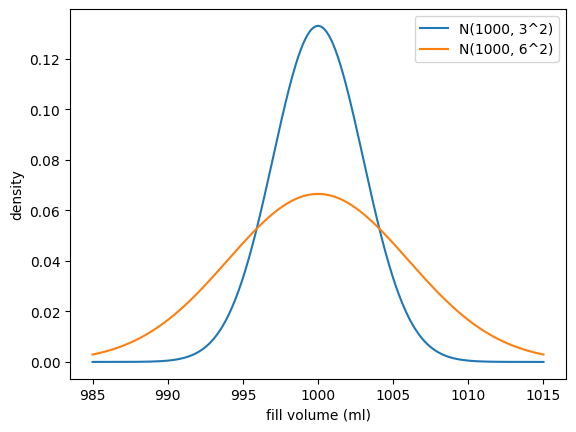

In [7]:
xs = np.linspace(985, 1015, 400)
for sigma in (3, 6):
    plt.plot(xs, stats.norm.pdf(xs, loc=1000, scale=sigma), label=f"N(1000, {sigma}^2)")
plt.xlabel("fill volume (ml)"); plt.ylabel("density"); plt.legend()
plt.show()

Slide: *Standardisation: one table for all normal distributions*.
$Z=(X-\mu)/\sigma\sim N(0,1)$. Milk bottle $X\sim N(1000,3^2)$:
$P(X\le 997)=\Phi(-1)=1-\Phi(1)=0.1587$.

In words: $z$ is the distance from the mean in standard deviations.

In [8]:
z = (997 - 1000) / 3
print(z, round(stats.norm.cdf(z), 4), round(stats.norm.cdf(997, loc=1000, scale=3), 4))   # -1.0 0.1587 0.1587

-1.0 0.1587 0.1587


Slide: *Probabilities as areas -- the four basic cases*.
$P(Z>z)=1-\Phi(z)$, $\ \Phi(-z)=1-\Phi(z)$, $\ P(a\le Z\le b)=\Phi(b)-\Phi(a)$.

In [9]:
print(round(stats.norm.cdf(0.75), 4))                       # P(Z <= 0.75):       0.7734
print(round(stats.norm.sf(0.75), 4))                        # P(Z > 0.75):        0.2266
print(round(stats.norm.cdf(-0.75), 4))                      # P(Z <= -0.75):      0.2266
print(round(stats.norm.cdf(1) - stats.norm.cdf(-0.5), 4))   # P(-0.5 <= Z <= 1):  0.5328

0.7734
0.2266
0.2266
0.5328


Slides: *Standard normal table $\Phi(z)=P(Z\le z)$ (1/2), (2/2)*. Row $=z$ to one decimal,
column $=$ second decimal.

In [10]:
print(" z    " + "  ".join(f" .0{j} " for j in range(10)))
for i in range(30):
    z0 = i / 10
    print(f"{z0:3.1f}  " + "  ".join(f"{stats.norm.cdf(z0 + j / 100):.4f}" for j in range(10)))

 z     .00    .01    .02    .03    .04    .05    .06    .07    .08    .09 
0.0  0.5000  0.5040  0.5080  0.5120  0.5160  0.5199  0.5239  0.5279  0.5319  0.5359
0.1  0.5398  0.5438  0.5478  0.5517  0.5557  0.5596  0.5636  0.5675  0.5714  0.5753
0.2  0.5793  0.5832  0.5871  0.5910  0.5948  0.5987  0.6026  0.6064  0.6103  0.6141
0.3  0.6179  0.6217  0.6255  0.6293  0.6331  0.6368  0.6406  0.6443  0.6480  0.6517
0.4  0.6554  0.6591  0.6628  0.6664  0.6700  0.6736  0.6772  0.6808  0.6844  0.6879
0.5  0.6915  0.6950  0.6985  0.7019  0.7054  0.7088  0.7123  0.7157  0.7190  0.7224
0.6  0.7257  0.7291  0.7324  0.7357  0.7389  0.7422  0.7454  0.7486  0.7517  0.7549
0.7  0.7580  0.7611  0.7642  0.7673  0.7704  0.7734  0.7764  0.7794  0.7823  0.7852
0.8  0.7881  0.7910  0.7939  0.7967  0.7995  0.8023  0.8051  0.8078  0.8106  0.8133
0.9  0.8159  0.8186  0.8212  0.8238  0.8264  0.8289  0.8315  0.8340  0.8365  0.8389
1.0  0.8413  0.8438  0.8461  0.8485  0.8508  0.8531  0.8554  0.8577  0.8599  0.8621
1

Slide: *Reading the table -- forwards and backwards*. Forwards: $\Phi(z)$ (`cdf`);
backwards: the quantile $z_p$ with $\Phi(z_p)=p$ (`ppf`).

In words: the famous $1.96$ is the $0.975$-quantile of $N(0,1)$.

In [11]:
print(round(stats.norm.cdf(0.75), 4))                       # Phi(0.75)              -> 0.7734
print(round(stats.norm.ppf(0.95), 4))                       # quantile z_0.95        -> 1.6449
print(round(stats.norm.cdf(997, loc=1000, scale=3), 4))     # P(X <= 997), N(1000,9) -> 0.1587
print(round(stats.norm.cdf(1.64), 4), round(stats.norm.cdf(1.65), 4), round(stats.norm.ppf(0.975), 2))  # 0.9495 0.9505 1.96

0.7734
1.6449
0.1587
0.9495 0.9505 1.96


#### Exercise -- normal distribution: fill volume

The fill volume of orange-juice bottles is $X\sim N(1000,\,10^2)$ (ml); the legal minimum is $985$ ml.

a) $P(X<985)$? b) $P(990\le X\le 1015)$? c) Which volume $x_{0.95}$ is exceeded by only $5\,\%$ of
the bottles? d) To which setpoint $\mu$ must the plant be adjusted (same $\sigma$) so that at most
$1\,\%$ of the bottles are underfilled?

In [12]:
# Your turn: standardise or use stats.norm(loc=..., scale=...)
mu, sigma = 1000, 10

**Solution**

Rules: `cdf` gives $P(X\le x)$, `ppf` the quantile; d) solves $(985-\mu)/10=z_{0.01}$.

In [13]:
X = stats.norm(loc=1000, scale=10)          # X ~ N(1000, 10^2)
print(f"a) {X.cdf(985):.4f}")
print(f"b) {X.cdf(1015) - X.cdf(990):.4f}")
print(f"c) {X.ppf(0.95):.2f}")
print(f"d) {985 - stats.norm.ppf(0.01) * 10:.2f}")   # mu = 985 - z_0.01 * sigma
# table solution of d): z_0.99 = 2.33 -> mu = 985 + 2.33 * 10 = 1008.3

a) 0.0668
b) 0.7745
c) 1016.45
d) 1008.26


### 1.3 Sampling distribution and CLT

Slides: *Estimators are random variables* and *The standard error: how much $\bar X$ wobbles*.
$\mathrm{SE}(\bar X)=\sigma/\sqrt n$ (or $s/\sqrt n$ when $\sigma$ is estimated).

In words: every new sample gives a new $\bar x$ and a new $s$; the standard error is the spread of
$\bar X$ from sample to sample, not the spread of the data.

In [14]:
rng = np.random.default_rng(3)
for k in range(5):                                   # five new samples of n = 9 bottles
    sample = rng.normal(1000, 3, size=9)
    print(f"sample {k + 1}: mean = {sample.mean():.2f}, s = {sample.std(ddof=1):.2f}")
print("SE = sigma / sqrt(n) =", 3 / np.sqrt(9))      # 1.0 ml

sample 1: mean = 998.52, s = 3.99
sample 2: mean = 1000.35, s = 3.85
sample 3: mean = 1001.55, s = 2.50
sample 4: mean = 1000.51, s = 1.93
sample 5: mean = 998.35, s = 3.67
SE = sigma / sqrt(n) = 1.0


Slides: *The central limit theorem -- a simulation* and *The central limit theorem with Python*.
Right-skewed processing times (gamma distribution, $\mu=12$, $\sigma=6$ minutes); $20\,000$ samples.
For large $n$: $\bar X\overset{\text{approx.}}{\sim}N(\mu,\sigma^2/n)$.

In words: whatever the shape of the data, the sample mean becomes approximately normal and narrows
like $\sigma/\sqrt n$.

In [15]:
rng = np.random.default_rng(42)                            # fixed seed
times = rng.gamma(shape=4, scale=3, size=(20_000, 36))     # 20 000 shifts x 36 orders
means = times.mean(axis=1)                                 # one mean per shift
print(round(times.mean(), 1), round(times.std(), 1))       # single values: 12.0 6.0
print(round(means.mean(), 3), round(means.std(), 2))       # shift means:   12.003 0.99
print(round(stats.skew(times.ravel()), 2), round(stats.skew(means), 2))   # skewness: 1.0 0.15
print(round(np.mean(means > 13.5), 4))                     # share of shifts above 13.5 min: 0.0698
print(round(stats.norm.sf(13.5, loc=12, scale=6 / np.sqrt(36)), 4))       # CLT approximation: 0.0668

12.0 6.0
12.003 0.99
1.0 0.15
0.0698
0.0668


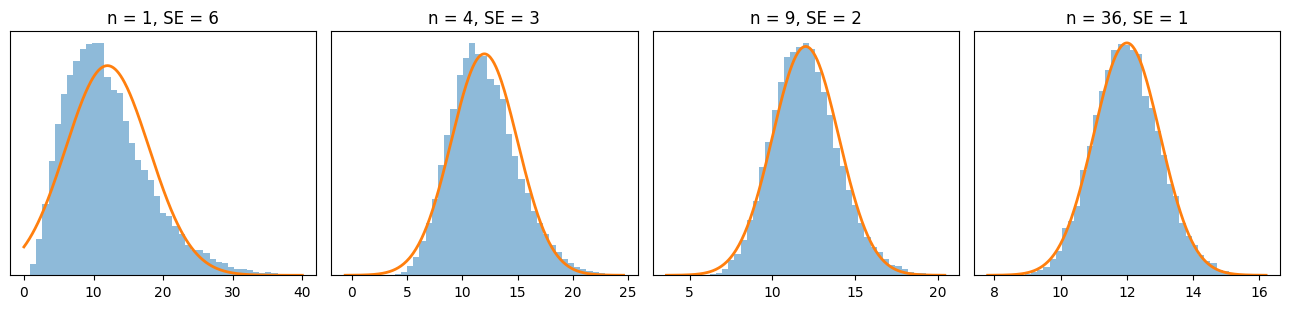

In [16]:
# the picture of the simulation slide: histograms of 20 000 sample means for n = 1, 4, 9, 36
rng = np.random.default_rng(42)
fig, axes = plt.subplots(1, 4, figsize=(13, 3.2))
for ax, n in zip(axes, [1, 4, 9, 36]):
    m = rng.gamma(4, 3, size=(20_000, n)).mean(axis=1)
    se = 6 / np.sqrt(n)
    lo, hi = (0, 40) if n == 1 else (12 - 4.2 * se, 12 + 4.2 * se)
    ax.hist(m, bins=np.linspace(lo, hi, 46), density=True, alpha=0.5)
    grid = np.linspace(lo, hi, 300)
    ax.plot(grid, stats.norm.pdf(grid, 12, se), lw=2)
    ax.set_title(f"n = {n}, SE = {se:.2g}")
    ax.set_yticks([])
plt.tight_layout()
plt.show()

Slide: *The central limit theorem -- formal statement* (Lindeberg--Lévy):
$Z_n=\dfrac{\bar X-\mu}{\sigma/\sqrt n}\xrightarrow{d}N(0,1)$. Rule of thumb $n\gtrsim30$; for normal
data the result holds exactly for every $n$. The CLT is about $\bar X$ -- not about single values.

#### Exercise -- central limit theorem: processing times

The processing time $X$ of a customer order is right-skewed with $\mu=12$ and $\sigma=6$ minutes;
$n=36$ orders per shift are processed independently.

a) How is $\bar X$ (approximately) distributed? b) $P(\bar X>13.5)$? c) $P(X>13.5)$ for a single
order *if* $X$ were normal -- and why does this need that assumption while b) does not?
d) How many orders give a standard error of at most $0.5$ minutes?

In [17]:
# Your turn: CLT: Xbar ~ N(mu, sigma^2 / n) approximately
mu, sigma, n = 12, 6, 36

**Solution**

Rules: $\mathrm{SE}=\sigma/\sqrt n$; the CLT concerns $\bar X$ only; d) solves $6/\sqrt n\le0.5$.

In [18]:
print(f"a) SE = {6 / np.sqrt(36):.1f}  ->  Xbar ~ N(12, 1^2) approximately")
print(f"b) {stats.norm.sf(13.5, loc=12, scale=6 / np.sqrt(36)):.4f}")   # mean
print(f"c) {stats.norm.sf(13.5, loc=12, scale=6):.4f}")                 # single value, IF normal
print(f"d) {(6 / 0.5) ** 2:.0f}")
# comparison under the right-skewed gamma model of the simulation slide
print(round(stats.gamma(a=4, scale=3).sf(13.5), 3),                     # single value: 0.342
      round(stats.gamma(a=4 * 36, scale=3 / 36).sf(13.5), 3))           # mean of 36:   0.071

a) SE = 1.0  ->  Xbar ~ N(12, 1^2) approximately
b) 0.0668
c) 0.4013
d) 144
0.342 0.071


## 2 Confidence Intervals

### 2.1 Motivation and intuition

Slide: *Why divide by the standard error?* The same raw deviation $\bar x-\mu_0=8-10=-2$ is
ordinary or far out, depending on $\mathrm{SE}=\sigma/\sqrt n$: $z=(\bar x-\mu_0)/\mathrm{SE}$.

In words: "how many standard errors" is a universal ruler.

In [19]:
for sigma, n in [(6, 9), (4, 100)]:
    se = sigma / np.sqrt(n)
    print(f"sigma = {sigma}, n = {n:>3}: SE = {se:.1f}, z = {(8 - 10) / se:.1f}")

sigma = 6, n =   9: SE = 2.0, z = -1.0
sigma = 4, n = 100: SE = 0.4, z = -5.0


#### Exercise -- standard error: packing flour

A mill packs flour into $500$ g bags; single bags scatter with $\sigma=8$ g.

a) Standard error of $\bar X$ for $n=16$ and $n=64$? b) A sample gives $\bar x=497$ g: how many
standard errors below $\mu_0=500$ g is that for $n=16$ and $n=64$? Which finding is conspicuous?
c) How much do the single bags scatter with $64$ instead of $16$ bags?

In [20]:
# Your turn: SE = sigma / sqrt(n), z = (xbar - mu0) / SE
sigma, xbar, mu0 = 8, 497, 500

**Solution**

Rule: $\mathrm{SE}=\sigma/\sqrt n$; compare $|z|$ with $1.96$ (central $95\,\%$ of $N(0,1)$).

In [21]:
for n in (16, 64):
    se = 8 / np.sqrt(n)
    z = (497 - 500) / se
    print(f"n = {n}: SE = {se:.0f} g, z = {z:.1f}, conspicuous: {abs(z) > 1.96}")
print(round(2 * stats.norm.sf(1.5), 4))      # n = 16: P(|Z| >= 1.5) = 0.1336 -> ordinary
print("c) sigma stays 8 g -- n only shrinks the spread of the mean")

n = 16: SE = 2 g, z = -1.5, conspicuous: False
n = 64: SE = 1 g, z = -3.0, conspicuous: True
0.1336
c) sigma stays 8 g -- n only shrinks the spread of the mean


Slide: *How we read probability: the frequentist view*. Parameters are fixed, the data (and all
intervals built from them) are random; "$95\,\%$ confidence" describes the procedure across repeated
samples. The coverage simulation in 2.2 shows this in action.

### 2.2 Known variance

Slides: *Our story: filling milk* to *Milk example: calculation*. With known $\sigma$:
$\text{CI}_{1-\alpha}=\bigl[\bar x\pm z_{1-\alpha/2}\,\sigma/\sqrt n\bigr]$, margin of error
$e=z_{1-\alpha/2}\,\sigma/\sqrt n$.

In words: estimate $\pm$ critical value $\times$ standard error.

In [22]:
xbar, sigma, n = milk.mean(), 3, len(milk)
z = stats.norm.ppf(0.975)                    # 1.96
e = z * sigma / np.sqrt(n)                   # margin of error
print(f"xbar = {xbar}, z = {z:.2f}, e = {e:.2f}, CI = [{xbar - e:.2f}, {xbar + e:.2f}]")   # [999.04, 1002.96]

xbar = 1001.0, z = 1.96, e = 1.96, CI = [999.04, 1002.96]


#### Exercise -- filling cream (known variance)

Cream cups (label $250$ g), known variance $\sigma^2=4\ \text{g}^2$, $n=16$ cups:
251, 248, 248, 249, 250, 251, 247, 246, 252, 251, 248, 247, 246, 249, 248, 252.
Compute the $95\,\%$ CI for $\mu$ with known variance. Is $250$ g inside?

In [23]:
# Your turn: 95% CI with sigma = 2 known
cream = np.array([251, 248, 248, 249, 250, 251, 247, 246,
                  252, 251, 248, 247, 246, 249, 248, 252])

**Solution**

Rule: $\text{CI}=\bigl[\bar x\pm z_{0.975}\,\sigma/\sqrt n\bigr]$ with $z_{0.975}=1.96$.

In [24]:
xbar = cream.sum() / len(cream)                         # 3983 / 16
e = 1.96 * 2 / np.sqrt(16)                              # 0.98
print(f"sum = {cream.sum()}, xbar = {xbar}, e = {e:.2f}, CI = [{xbar - e:.2f}, {xbar + e:.2f}]")   # [247.96, 249.92]
print("250 inside?", xbar - e <= 250 <= xbar + e)       # False -> indication of a problem

sum = 3983, xbar = 248.9375, e = 0.98, CI = [247.96, 249.92]
250 inside? False


Slide: *What does "95 % confidence" mean?* Simulate many samples from the true $N(1000,3^2)$ and
build the $95\,\%$ CI each time: about $95\,\%$ of the intervals cover $\mu=1000$.

19 of the first 20 intervals cover mu; 0.9465 of all 10 000


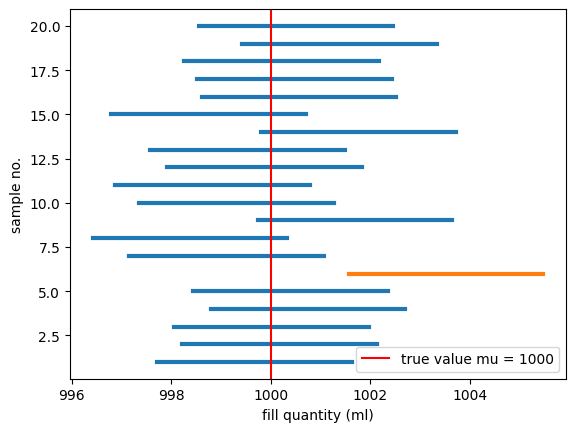

In [25]:
rng = np.random.default_rng(2026)
means = rng.normal(1000, 3, size=(10_000, 9)).mean(axis=1)    # 10 000 samples of n = 9
e = 1.96 * 3 / np.sqrt(9)
covered = (means - e <= 1000) & (1000 <= means + e)
print(covered[:20].sum(), "of the first 20 intervals cover mu;", covered.mean(), "of all 10 000")
for i, m in enumerate(means[:20], start=1):                  # the picture of the slide
    plt.plot([m - e, m + e], [i, i], color="tab:blue" if covered[i - 1] else "tab:orange", lw=3)
plt.axvline(1000, color="red", label="true value mu = 1000")
plt.xlabel("fill quantity (ml)"); plt.ylabel("sample no."); plt.legend()
plt.show()

Slides: *A common misconception* and *Three correct ways to read a confidence interval*.
$\mu$ is fixed; the bounds are random. Correct readings: coverage of the procedure, the values of
$\mu$ compatible with the data, and the set of $\mu_0$ a two-sided test would not reject.

Slide: *Do not confuse: CI vs. fluctuation interval*. Single values scatter with $\sigma$
($\mu\pm1.96\,\sigma$); the mean scatters with $\sigma/\sqrt n$ -- and that is the width of the CI.

In [26]:
print("single bottles: ", [round(1000 - 1.96 * 3, 2), round(1000 + 1.96 * 3, 2)])   # [994.12, 1005.88]
print("mean of n = 9:  ", [round(1000 - 1.96 * 1, 2), round(1000 + 1.96 * 1, 2)])   # [998.04, 1001.96]

single bottles:  [994.12, 1005.88]
mean of n = 9:   [998.04, 1001.96]


#### Exercise -- reading a confidence interval correctly

Cream sample ($n=16$, $\bar x=248.9375$ g, $\sigma=2$ g known): $95\,\%$ CI $[247.96;\,249.92]$.
True or false?
1. "With $95\,\%$ probability $\mu$ lies between $247.96$ and $249.92$ g."
2. "About $95\,\%$ of all cups weigh between $247.96$ and $249.92$ g."
3. "In very many repetitions, about $95\,\%$ of the intervals computed this way contain $\mu$."
4. "The target $250$ g is not compatible with the data at the $95\,\%$ level."
5. "A $99\,\%$ interval from the same data would be narrower, because it is more certain."

In [27]:
# Your turn: note true/false for 1-5; statements 2 and 5 can be checked numerically
xbar, sigma, n = 248.9375, 2, 16

**Solution**

1 **false** ($\mu$ is fixed; $0.95$ belongs to the procedure), 2 **false** (single cups scatter
with $\sigma$, see below), 3 **true** (coverage), 4 **true** ($250\notin$ CI), 5 **false** (wider, see below).

In [28]:
xbar = 248.9375
print("2) range of single cups:", [round(xbar - 1.96 * 2, 2), round(xbar + 1.96 * 2, 2)])   # [245.02, 252.86]
e99 = 2.576 * 2 / np.sqrt(16)
print(f"5) 99% margin: {e99:.3f}, CI = [{xbar - e99:.2f}, {xbar + e99:.2f}]")             # 1.288 [247.65, 250.23]

2) range of single cups: [245.02, 252.86]
5) 99% margin: 1.288, CI = [247.65, 250.23]


### 2.3 Length of the confidence interval

Slide: *What does the length depend on?* $L=2\,z_{1-\alpha/2}\,\sigma/\sqrt n$: longer for more
confidence and larger $\sigma$, shorter with $1/\sqrt n$.

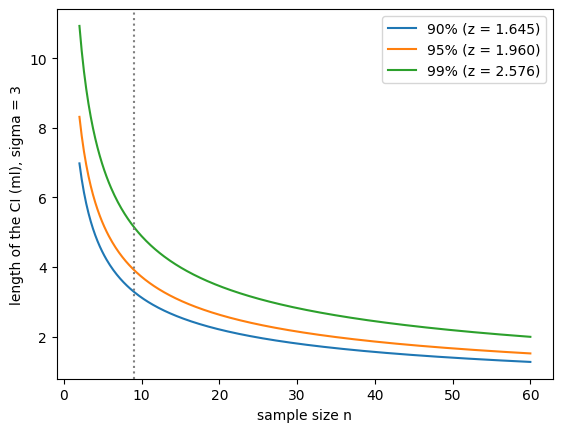

In [29]:
ns = np.linspace(2, 60, 400)
for conf in (0.90, 0.95, 0.99):
    zq = stats.norm.ppf(1 - (1 - conf) / 2)
    plt.plot(ns, 2 * zq * 3 / np.sqrt(ns), label=f"{conf:.0%} (z = {zq:.3f})")
plt.axvline(9, ls=":", color="gray")
plt.xlabel("sample size n"); plt.ylabel("length of the CI (ml), sigma = 3"); plt.legend()
plt.show()

Slide: *Different confidence levels -- milk*. Higher confidence level $\Rightarrow$ wider interval.

In [30]:
for conf in (0.90, 0.95, 0.99):
    zq = stats.norm.ppf(1 - (1 - conf) / 2)
    e = zq * 3 / np.sqrt(9)
    print(f"{conf:.0%}: z = {zq:.3f}, CI = [{1001 - e:.2f}, {1001 + e:.2f}]")

90%: z = 1.645, CI = [999.36, 1002.64]
95%: z = 1.960, CI = [999.04, 1002.96]
99%: z = 2.576, CI = [998.42, 1003.58]


Slide: *Planning the sample size*. Solve $e=z_{1-\alpha/2}\,\sigma/\sqrt n$ for $n$:
$n\ge\bigl(z_{1-\alpha/2}\,\sigma/e\bigr)^2$, rounded **up**.

In words: halving the margin of error needs four times as many observations.

In [31]:
def n_required(conf, sigma, e):
    z = stats.norm.ppf(1 - (1 - conf) / 2)
    return math.ceil((z * sigma / e) ** 2)

print(n_required(0.95, 3, 1))     # 35 bottles for a margin of +-1 ml

35


#### Exercise -- how many bottles? (planning the sample size)

Milk, $\sigma=3$ ml known, $95\,\%$ CI with margin of error at most $e=1$ ml.
a) Margin of error with $n=9$? b) Minimum $n$ for $e\le1$? c) The same at $99\,\%$?
d) At $95\,\%$ with $e\le0.5$? (Hint: $z_{0.975}=1.96$, $z_{0.995}=2.576$; round $n$ up.)

In [32]:
# Your turn: n >= (z * sigma / e)^2, rounded up
sigma = 3

**Solution**

Rule: $n\ge(z_{1-\alpha/2}\,\sigma/e)^2$; table values $1.96$ and $2.576$.

In [33]:
print("a)", round(1.96 * 3 / np.sqrt(9), 2))                          # 1.96 ml
for label, zq, e in [("b)", 1.96, 1), ("c)", 2.576, 1), ("d)", 1.96, 0.5)]:
    print(label, round((zq * 3 / e) ** 2, 2), "->", math.ceil((zq * 3 / e) ** 2))
# with the function of the slide (unrounded quantiles):
print(n_required(0.95, 3, 1), n_required(0.99, 3, 1), n_required(0.95, 3, 0.5))   # 35 60 139

a) 1.96
b) 34.57 -> 35
c) 59.72 -> 60
d) 138.3 -> 139
35 60 139


### 2.4 Unknown variance

Slides: *More realistic: the variance is unknown* and *Why the $t$-distribution?*
$s^2=\frac{1}{n-1}\sum(x_i-\bar x)^2$, $\ T_n=\dfrac{\bar X-\mu}{s/\sqrt n}\sim t_{n-1}$ (normal data).

In words: $s$ is random too, so $T_n$ has heavier tails than $N(0,1)$ -- for large $n$ the
difference vanishes.

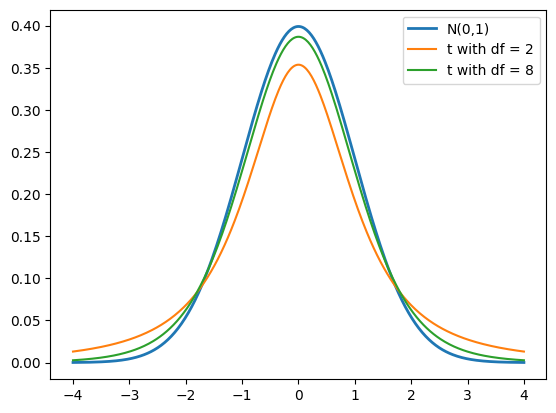

In [34]:
grid = np.linspace(-4, 4, 400)
plt.plot(grid, stats.norm.pdf(grid), label="N(0,1)", lw=2)
for df in (2, 8):
    plt.plot(grid, stats.t.pdf(grid, df=df), label=f"t with df = {df}")
plt.legend(); plt.show()

Slide: *Milk example with unknown variance*:
$\text{CI}=\bigl[\bar x\pm t_{1-\alpha/2,\,n-1}\,s/\sqrt n\bigr]$.

In [35]:
s = milk.std(ddof=1)                         # 3.7749
t8 = stats.t.ppf(0.975, df=8)                # 2.3060
e = t8 * s / np.sqrt(9)                      # 2.9017
print(f"s = {s:.4f}, t = {t8:.4f}, e = {e:.4f}, CI = [{1001 - e:.2f}, {1001 + e:.2f}]")   # [998.10, 1003.90]

s = 3.7749, t = 2.3060, e = 2.9017, CI = [998.10, 1003.90]


Slide: *Summary: known vs. unknown variance*. The $t$-quantile approaches $z_{0.975}=1.96$ as $n$ grows.

In [36]:
for n in (9, 30, 100, 1000):
    print(f"n = {n:>4}: t_0.975;{n - 1} = {stats.t.ppf(0.975, df=n - 1):.3f}   (z = 1.960)")

n =    9: t_0.975;8 = 2.306   (z = 1.960)
n =   30: t_0.975;29 = 2.045   (z = 1.960)
n =  100: t_0.975;99 = 1.984   (z = 1.960)
n = 1000: t_0.975;999 = 1.962   (z = 1.960)


Slide: *Confidence intervals with Python*. `stats.norm.interval(conf, loc=xbar, scale=SE)` and
`stats.t.interval(conf, df=n-1, loc=xbar, scale=s/sqrt(n))` return the central interval.

In [37]:
xbar, n, s = milk.mean(), len(milk), milk.std(ddof=1)    # 1001.0, 9, 3.7749
print(f"{stats.norm.ppf(0.975):.4f} {stats.t.ppf(0.975, df=n - 1):.4f}")         # quantiles: 1.9600 2.3060
for conf in (0.90, 0.95, 0.99):                          # sigma = 3 known -> N(0,1)
    lo, hi = stats.norm.interval(conf, loc=xbar, scale=3 / np.sqrt(n))
    print(f"z, {conf:.0%}: [{lo:.2f}, {hi:.2f}]")
lo, hi = stats.t.interval(0.95, df=n - 1, loc=xbar, scale=s / np.sqrt(n))
print(f"t, 95%: [{lo:.2f}, {hi:.2f}]")                   # sigma estimated -> t_(n-1)

1.9600 2.3060
z, 90%: [999.36, 1002.64]
z, 95%: [999.04, 1002.96]
z, 99%: [998.42, 1003.58]
t, 95%: [998.10, 1003.90]


#### Exercise -- filling cream (unknown variance)

The same $16$ cream cups, but $\sigma$ is now estimated from the sample.
Compute $s$ and the $95\,\%$ CI with unknown variance. Does the verdict on $250$ g change compared
with $[247.96;\,249.92]$? (Hint: $\sum(x_i-\bar x)^2=60.9375$, $t_{0.975;15}=2.1314$.)

In [38]:
# Your turn: s with ddof=1 and the t-quantile with df = 15
cream = np.array([251, 248, 248, 249, 250, 251, 247, 246,
                  252, 251, 248, 247, 246, 249, 248, 252])

**Solution**

Rule: as for known variance, but $z\to t_{0.975;15}$ and $\sigma\to s$.

In [39]:
ss = np.sum((cream - cream.mean()) ** 2)                # 60.9375
s = np.sqrt(ss / 15)                                    # 2.0156
e = stats.t.ppf(0.975, df=15) * s / np.sqrt(16)         # 1.0740
print(f"SS = {ss}, s^2 = {s ** 2:.4f}, s = {s:.4f}, e = {e:.4f}")              # 60.9375 4.0625 2.0156 1.0740
lo, hi = stats.t.interval(0.95, df=15, loc=cream.mean(), scale=s / np.sqrt(16))
print(f"CI = [{lo:.2f}, {hi:.2f}], 250 inside? {lo <= 250 <= hi}")   # [247.86, 250.01] True

SS = 60.9375, s^2 = 4.0625, s = 2.0156, e = 1.0740
CI = [247.86, 250.01], 250 inside? True


## 3 Hypothesis Tests

### 3.1 Idea and hypotheses

Slides: *What is a hypothesis test? -- intuition*, *The two hypotheses*, *Which hypothesis goes where?*
$H_0:\mu=\mu_0$ vs. $H_1:\mu\neq\mu_0$. We always argue under "$H_0$ is true"; the claim you want
to establish goes into $H_1$. No computation yet -- the next subsections compute.

### 3.2 From CI to test

Slides: *Bridge: confidence interval and test are the same* and *The duality on the number line*.
$\mu_0$ inside the $(1-\alpha)$-CI $\Leftrightarrow$ $|Z_n|\le z_{1-\alpha/2}$ $\Leftrightarrow$ keep $H_0$.

In [40]:
for name, x, mu0, sigma in [("milk", milk, 1000, 3), ("cream", cream, 250, 2)]:
    lo, hi = stats.norm.interval(0.95, loc=x.mean(), scale=sigma / np.sqrt(len(x)))
    verdict = "keep H0" if lo <= mu0 <= hi else "reject H0"
    print(f"{name}: CI = [{lo:.2f}, {hi:.2f}], mu0 = {mu0} -> {verdict}")

milk: CI = [999.04, 1002.96], mu0 = 1000 -> keep H0
cream: CI = [247.96, 249.92], mu0 = 250 -> reject H0


#### Exercise -- hypotheses and deciding with the CI

A bank plans with $\mu_0=30$ min per loan application; longer and shorter times matter equally.
$\sigma=6$ min known, $n=36$, $\bar x=32.8$ min, $\alpha=0.05$.
a) $H_0$, $H_1$? b) $95\,\%$ CI? c) Decide with the CI. d) Which of $\mu_0=31$, $33$, $35$ would a
two-sided $5\,\%$ test reject?

In [41]:
# Your turn: CI with sigma known, then check each mu0
xbar, sigma, n = 32.8, 6, 36

**Solution**

a) $H_0:\mu=30$ vs. $H_1:\mu\neq30$. Rule: $\mu_0$ inside the CI $\Leftrightarrow$ keep $H_0$.

In [42]:
se = 6 / np.sqrt(36)                                     # 1
lo, hi = 32.8 - 1.96 * se, 32.8 + 1.96 * se
print(f"b) CI = [{lo:.2f}, {hi:.2f}]")                   # [30.84, 34.76]
for mu0 in (30, 31, 33, 35):
    print(f"mu0 = {mu0}: |Z_n| = {abs(32.8 - mu0) / se:.2f} ->",
          "keep H0" if lo <= mu0 <= hi else "reject H0")

b) CI = [30.84, 34.76]
mu0 = 30: |Z_n| = 2.80 -> reject H0
mu0 = 31: |Z_n| = 1.80 -> keep H0
mu0 = 33: |Z_n| = 0.20 -> keep H0
mu0 = 35: |Z_n| = 2.20 -> reject H0


### 3.3 Known variance

Slides: *The critical value*, *The test recipe (known variance)*, *Milk test with known variance*.
$Z_n=\dfrac{\bar x-\mu_0}{\sigma/\sqrt n}$; reject $H_0$ if $|Z_n|>z_{1-\alpha/2}$.

In [43]:
z_n = (milk.mean() - 1000) / (3 / np.sqrt(9))
z_crit = stats.norm.ppf(0.975)
print(f"Z_n = {z_n:.3f}, critical value = {z_crit:.2f} ->", "reject H0" if abs(z_n) > z_crit else "keep H0")

Z_n = 1.000, critical value = 1.96 -> keep H0


### 3.4 Unknown variance

Slides: *Test with unknown variance* and *Milk test with unknown variance*.
$T_n=\dfrac{\bar x-\mu_0}{s/\sqrt n}\sim t_{n-1}$ under $H_0$; reject if $|T_n|>t_{1-\alpha/2,\,n-1}$.
The assumptions checklist (random sample, approx. normal or $n\gtrsim30$, direction and $\alpha$ fixed
in advance) applies to every test.

In [44]:
t_n = (milk.mean() - 1000) / (milk.std(ddof=1) / np.sqrt(9))
t_crit = stats.t.ppf(0.975, df=8)
print(f"T_n = {t_n:.4f}, critical value = {t_crit:.4f} ->", "reject H0" if abs(t_n) > t_crit else "keep H0")

T_n = 0.7947, critical value = 2.3060 -> keep H0


### 3.5 Tests with Python

Slide: *Hypothesis test with Python -- `ttest_1samp`*. Two-sided $t$-test with unknown variance; `.confidence_interval()` adds the CI.

In [45]:
res = stats.ttest_1samp(milk, popmean=1000)    # two-sided by default
ci = res.confidence_interval(confidence_level=0.95)
print(f"t = {res.statistic:.4f}, df = {res.df}, p = {res.pvalue:.4f}")
print(f"95% CI: [{ci.low:.2f}, {ci.high:.2f}]")

t = 0.7947, df = 8, p = 0.4497
95% CI: [998.10, 1003.90]


### 3.6 Exercises

#### Exercise -- cream test

Cream, label $250$ g, $\sigma^2=4$ known, $n=16$, $\bar x=248.9375$, $\alpha=0.05$, $\mu_0=250$.
Test two-sided (a) with known variance, (b) with unknown variance ($s=2.0156$, $t_{0.975;15}=2.1314$).

In [46]:
# Your turn: Z_n and T_n, compare with the critical values
xbar, mu0, n = 248.9375, 250, 16

**Solution**

Rule: reject if $|Z_n|>1.96$ resp. $|T_n|>t_{0.975;15}$.

In [47]:
z_n = (248.9375 - 250) / (2 / np.sqrt(16))
t_n = (248.9375 - 250) / (cream.std(ddof=1) / np.sqrt(16))
print(f"a) Z_n = {z_n:.3f}, |Z_n| > 1.96: {abs(z_n) > 1.96}")                                    # -2.125 True -> reject
print(f"b) T_n = {t_n:.4f}, |T_n| > {stats.t.ppf(0.975, 15):.4f}: {abs(t_n) > stats.t.ppf(0.975, 15)}")  # -2.1086 False -> keep

a) Z_n = -2.125, |Z_n| > 1.96: True
b) T_n = -2.1086, |T_n| > 2.1314: False


Slide: *Milk vs. cream -- the picture behind both decisions*. One curve (the $H_0$ world), two bars
($\pm1.96$): milk's $Z_n=1.00$ stays inside, cream's $Z_n=-2.125$ lands beyond.

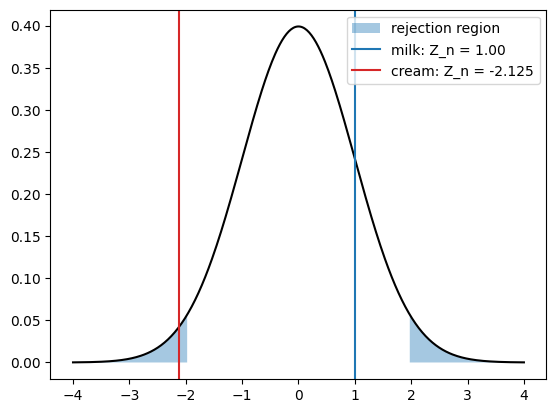

In [48]:
grid = np.linspace(-4, 4, 400)
plt.plot(grid, stats.norm.pdf(grid), color="black")
plt.fill_between(grid, stats.norm.pdf(grid), where=np.abs(grid) > 1.96, alpha=0.4, label="rejection region")
plt.axvline(1.00, color="tab:blue", label="milk: Z_n = 1.00")
plt.axvline(-2.125, color="tab:red", label="cream: Z_n = -2.125")
plt.legend(); plt.show()

#### Exercise -- reaction time (large sample)

A training programme is meant to change the baseline reaction time $\mu_0=250$ ms. $n=50$,
$\bar x=242$, $s=30$. Test two-sided at $\alpha=0.05$ (hint: $t_{0.975;49}=2.0096$).

In [49]:
# Your turn: T_n, critical value and two-sided p-value
xbar, s, n, mu0 = 242, 30, 50, 250

**Solution**

In [50]:
t_n = (242 - 250) / (30 / np.sqrt(50))
print(f"T_n = {t_n:.4f}, critical value = {stats.t.ppf(0.975, 49):.4f}")   # |T_n| < 2.0096 -> keep H0
print(f"p = {2 * stats.t.cdf(-abs(t_n), df=49):.4f}")                     # 0.0653

T_n = -1.8856, critical value = 2.0096
p = 0.0653


#### Exercise -- delivery time (complete $t$-test by hand)

Guaranteed mean delivery time $\mu_0=48$ h; both directions matter. $n=8$ shipments (h):
51, 39, 49, 41, 47, 43, 45, 45. Approximately normal, $\sigma$ unknown, $\alpha=0.05$.
a) $\bar x$ and $s$. b) $H_0$/$H_1$, $T_n$, decision with the critical value ($t_{0.975;7}=2.3646$).
c) $95\,\%$ CI and duality.

In [51]:
# Your turn: table of deviations, s with n - 1, T_n, CI
delivery = np.array([51, 39, 49, 41, 47, 43, 45, 45])    # hours

**Solution**

$H_0:\mu=48$ vs. $H_1:\mu\neq48$. Rules: $s^2=\sum(x_i-\bar x)^2/(n-1)$, reject if $|T_n|>2.3646$.

In [52]:
delivery = np.array([51, 39, 49, 41, 47, 43, 45, 45])    # hours
dev = delivery - delivery.mean()
print(dev, np.sum(dev ** 2))                              # deviations, sum of squares 112
print(delivery.mean(), delivery.std(ddof=1), round(stats.t.ppf(0.975, df=7), 4))   # 45.0 4.0 2.3646
print(round(delivery.std(ddof=1) / np.sqrt(8), 4))       # standard error 1.4142
res = stats.ttest_1samp(delivery, popmean=48)            # two-sided
ci = res.confidence_interval(confidence_level=0.95)
print(f"t = {res.statistic:.4f}, df = {res.df}, p = {res.pvalue:.4f}")
print(f"95% CI: [{ci.low:.2f}, {ci.high:.2f}]")

[ 6. -6.  4. -4.  2. -2.  0.  0.] 112.0
45.0 4.0 2.3646
1.4142
t = -2.1213, df = 7, p = 0.0716
95% CI: [41.66, 48.34]


Slide: *Recap -- and one limitation of the recipe*. Milk ($|Z_n|=1.000$, keep), cream with known
$\sigma$ ($|Z_n|=2.125$, reject), cream with unknown $\sigma$ ($|T_n|=2.109$ vs. $2.131$, keep):
the bare yes/no hides how close the call was -- the $p$-value of section 4 shows it.

## 4 The $p$-Value

### 4.1 Concept

Slides: *The $p$-value -- intuition, graphically, definition*, *Decision rule*, *Two rules, one
decision*. $p=P(\text{statistic at least as extreme as observed}\mid H_0)$; reject $H_0$ if $p<\alpha$.

In words: the smaller $p$, the more surprising the data would be if $H_0$ were true.

Slide: *Both rules, one verdict -- worked example* (cream, two-sided, known $\sigma$, $Z_n=-2.125$).

True 0.0336


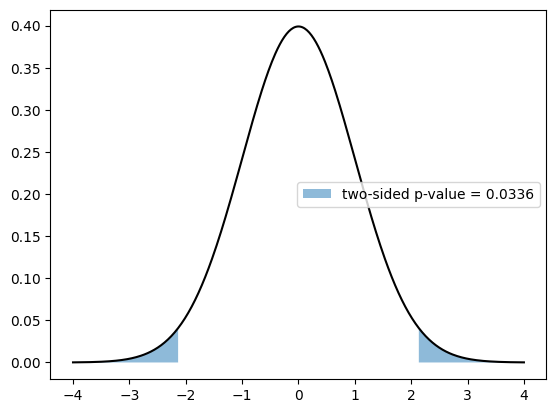

In [53]:
z_n = -2.125
print(abs(z_n) > stats.norm.ppf(0.975), round(2 * stats.norm.cdf(-abs(z_n)), 4))   # True 0.0336 -> both: reject
grid = np.linspace(-4, 4, 400)
plt.plot(grid, stats.norm.pdf(grid), color="black")
plt.fill_between(grid, stats.norm.pdf(grid), where=np.abs(grid) >= abs(z_n), alpha=0.5,
                 label="two-sided p-value = 0.0336")
plt.legend(); plt.show()

#### Exercise -- $p$-value and the choice of $\alpha$

A two-sided test with known variance yields $Z_n=1.85$. Compute the $p$-value and decide at
$\alpha=0.05$ and $\alpha=0.10$; check both with the critical values $z_{0.975}=1.96$, $z_{0.95}=1.645$.
(Table: $\Phi(1.85)=0.9678$.)

In [54]:
# Your turn: two-sided p = 2 * (1 - Phi(|Z_n|))
z_n = 1.85

**Solution**

Rule: $p=2\,(1-\Phi(|Z_n|))$; reject if $p<\alpha$.

In [55]:
print(round(2 * (1 - 0.9678), 4), round(2 * stats.norm.sf(1.85), 4))     # table 0.0644, exact 0.0643
for alpha, zc in [(0.05, 1.96), (0.10, 1.645)]:
    p = 2 * stats.norm.sf(1.85)
    print(f"alpha = {alpha}: p < alpha: {p < alpha}, |Z_n| > {zc}: {1.85 > zc}")   # keep / reject

0.0644 0.0643
alpha = 0.05: p < alpha: False, |Z_n| > 1.96: False
alpha = 0.1: p < alpha: True, |Z_n| > 1.645: True


### 4.2 Calculation

Slides: *Computing the $p$-value (two-sided)*, *$p$-value -- milk*, *$p$-value -- cream*, *$p$-values with Python*.
Known variance: $p=2\,\Phi(-|Z_n|)$; unknown variance: $p=2\,F_{t,n-1}(-|T_n|)$.

In [56]:
for x, mu0, sigma in [(milk, 1000, 3), (cream, 250, 2)]:
    n = len(x)
    z = (x.mean() - mu0) / (sigma / np.sqrt(n))           # sigma known
    t = (x.mean() - mu0) / (x.std(ddof=1) / np.sqrt(n))   # sigma estimated
    p_z = 2 * stats.norm.sf(abs(z))                       # 2 * (1 - Phi(|z|))
    p_t = 2 * stats.t.sf(abs(t), df=n - 1)                # 2 * (1 - F_t,n-1(|t|))
    print(f"z = {z:.4f}, p = {p_z:.4f} | t = {t:.4f}, p = {p_t:.4f}")

z = 1.0000, p = 0.3173 | t = 0.7947, p = 0.4497
z = -2.1250, p = 0.0336 | t = -2.1086, p = 0.0522


*Exact vs. table* (notes on the milk and cream slides): the printed tables give $0.3174$ for milk and only brackets elsewhere.

In [57]:
print(round(2 * (1 - 0.8413), 4))                                       # milk, Phi table: 0.3174
print(round(stats.t.ppf(0.90, 8), 3))                                   # 0.7947 < 1.397 -> p > 0.20
print(f"{2 * (1 - 0.9834):.4f} {2 * (1 - 0.9830):.4f}")                  # cream, Phi table: 0.0332 < p < 0.0340
print(round(stats.t.ppf(0.95, 15), 3), round(stats.t.ppf(0.975, 15), 3))  # 1.753 < 2.1086 < 2.131 -> 0.05 < p < 0.10

0.3174
1.397
0.0332 0.0340
1.753 2.131


Slides: *$p$-value -- typical misconceptions* and *Significant $\neq$ important -- the large-$n$ trap*.
$p$ is $P(\text{data}\mid H_0)$, not $P(H_0\mid\text{data})$; with huge $n$ even an irrelevant
deviation of $0.2$ ml becomes "highly significant".

In [58]:
for n in (9, 10_000):                     # observed xbar = 1000.2, mu0 = 1000, sigma = 3
    z_n = 0.2 / (3 / np.sqrt(n))
    print(f"n = {n:>6}: Z_n = {z_n:.2f}, p = {2 * stats.norm.sf(z_n):.4g}")

n =      9: Z_n = 0.20, p = 0.8415
n =  10000: Z_n = 6.67, p = 2.617e-11


### 4.3 Exercises

#### Exercise -- interpret the $p$-value (concept)

$p=0.03$, $\alpha=0.05$. Which statements are correct?
1. "There is a $3\,\%$ probability that $H_0$ is true."
2. "If $H_0$ were true, data this extreme occur in $3\,\%$ of samples."
3. "We reject $H_0$ at $\alpha=0.05$."
4. "The effect is large and important."

In [59]:
# Your turn: write down your answers, e.g. answers = {1: "wrong", 2: ..., 3: ..., 4: ...}
answers = {}

**Solution**

1 **wrong** ($p=P(\text{data}\mid H_0)$, not $P(H_0\mid\text{data})$), 2 **correct** (the definition),
3 **correct** ($0.03<0.05$), 4 **wrong** (significance $\neq$ effect size).

In [60]:
answers = {1: "wrong", 2: "correct", 3: "correct", 4: "wrong"}
p, alpha = 0.03, 0.05
print(answers, "| reject H0:", p < alpha)

{1: 'wrong', 2: 'correct', 3: 'correct', 4: 'wrong'} | reject H0: True


#### Exercise -- bracketing the $p$-value with the $t$-table

Delivery-time test: two-sided, $T_n=-2.1213$, df $=7$. Row df $=7$ of the $t$-table:
upper-tail probabilities $0.10, 0.05, 0.025, 0.01, 0.005$ $\to$ $1.415, 1.895, 2.365, 2.998, 3.499$.
a) Bracket the two-sided $p$-value. b) Decide at $\alpha=0.05$ and $0.10$. c) Exact value with Python?

In [61]:
# Your turn: bracket |T_n| in the df = 7 row, then double the tail areas
t_n, df = -2.1213, 7

**Solution**

Rule: two-sided $p=2\,P(T>|T_n|)$; $1.895<2.121<2.365$ $\Rightarrow$ $0.05<p<0.10$.

In [62]:
print([round(float(stats.t.isf(a, 7)), 3) for a in (0.10, 0.05, 0.025, 0.01, 0.005)])   # the table row
print(round(stats.t.sf(2.1213, 7), 4))                       # one tail: 0.0358, between 0.025 and 0.05
print(round(2 * stats.t.cdf(-2.1213, df=7), 4))              # exact two-sided p-value: 0.0716

[1.415, 1.895, 2.365, 2.998, 3.499]
0.0358
0.0716


#### Exercise -- coffee roastery (exam-style, from A to Z)

Target $\mu_0=1000$ g, $\sigma=40$ g known, $n=64$, $\bar x=1012$ g, two-sided, $\alpha=0.05$.
a) Hypotheses. b) SE and $Z_n$. c) Critical value and decision. d) $p$-value (table: $\Phi(2.40)=0.9918$).
e) $95\,\%$ CI. f) Second sample $n=25$, $\bar x=1012$, estimated $s=40$: $95\,\%$ CI with
$t_{0.975;24}=2.0639$ -- reject now?

In [63]:
# Your turn: Gauss test, p-value and CI; then the t-interval of f)
mu0, sigma, n, xbar = 1000, 40, 64, 1012

**Solution**

a) $H_0:\mu=1000$ vs. $H_1:\mu\neq1000$.

In [64]:
z = (1012 - 1000) / (40 / 64 ** 0.5)
print(40 / 64 ** 0.5, z, abs(z) > 1.96)                        # b), c): SE 5.0, Z_n 2.4 -> reject
print(z, round(2 * stats.norm.sf(abs(z)), 4))                   # d) 2.4 0.0164 (table: 2 * 0.0082)
print(f"[{1012 - 1.96 * 5:.1f}, {1012 + 1.96 * 5:.1f}]")         # e) [1002.2, 1021.8]
e_t = stats.t.ppf(0.975, df=24) * 40 / 5
print(f"{e_t:.2f} [{1012 - e_t:.2f}, {1012 + e_t:.2f}]")              # f) 16.51 [995.49, 1028.51] -> keep

5.0 2.4 True
2.4 0.0164
[1002.2, 1021.8]
16.51 [995.49, 1028.51]


## 5 One-Sided Tests

### 5.1 Motivation

Slides: *When only one direction matters*, *Business examples*, *How to find the critical value -- 3 steps*.
(1) direction from $H_1$; (2) one-sided: quantile $1-\alpha$, two-sided: $1-\alpha/2$;
(3) $\sigma$ known $\to z$, else $t$ with df $=n-1$.

In [65]:
print(round(stats.norm.ppf(0.975), 3), round(stats.norm.ppf(0.95), 3))          # z: two-sided 1.96, one-sided 1.645
print(f"{stats.t.ppf(0.975, df=11):.2f} {stats.t.ppf(0.95, df=11):.2f}")        # t, n = 12: 2.20 and 1.80

1.96 1.645
2.20 1.80


Slides: *Critical values of the standard normal $N(0,1)$* and *of the $t$-distribution*. The
$t$-table lists upper-tail probabilities (one-sided $\alpha$ | two-sided $\alpha/2$).

In [66]:
print("alpha   one-sided z  two-sided z")
for a in (0.10, 0.05, 0.02, 0.01, 0.001):
    print(f"{a:<7} {stats.norm.ppf(1 - a):>10.3f} {stats.norm.ppf(1 - a / 2):>11.3f}")
print("\ndf     0.10    0.05   0.025    0.01   0.005")
for df in (1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 15, 20, 30, 60):
    print(f"{df:<4}" + "".join(f"{stats.t.isf(a, df):8.3f}" for a in (0.10, 0.05, 0.025, 0.01, 0.005)))
print("inf " + "".join(f"{stats.norm.isf(a):8.3f}" for a in (0.10, 0.05, 0.025, 0.01, 0.005)))

alpha   one-sided z  two-sided z
0.1          1.282       1.645
0.05         1.645       1.960
0.02         2.054       2.326
0.01         2.326       2.576
0.001        3.090       3.291

df     0.10    0.05   0.025    0.01   0.005
1      3.078   6.314  12.706  31.821  63.657
2      1.886   2.920   4.303   6.965   9.925
3      1.638   2.353   3.182   4.541   5.841
4      1.533   2.132   2.776   3.747   4.604
5      1.476   2.015   2.571   3.365   4.032
6      1.440   1.943   2.447   3.143   3.707
7      1.415   1.895   2.365   2.998   3.499
8      1.397   1.860   2.306   2.896   3.355
9      1.383   1.833   2.262   2.821   3.250
10     1.372   1.812   2.228   2.764   3.169
15     1.341   1.753   2.131   2.602   2.947
20     1.325   1.725   2.086   2.528   2.845
30     1.310   1.697   2.042   2.457   2.750
60     1.296   1.671   2.000   2.390   2.660
inf    1.282   1.645   1.960   2.326   2.576


Slides: *How to read the tables -- worked lookups* ($n=10$, df $=9$) and *Why the $t$-table ends in the normal*.

2.262 1.833


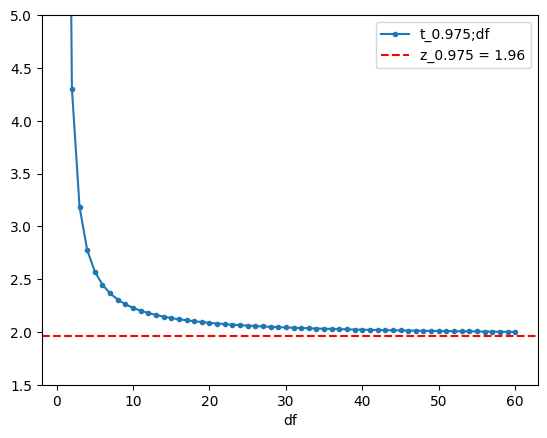

In [67]:
print(round(stats.t.ppf(0.975, df=9), 3), round(stats.t.ppf(0.95, df=9), 3))   # two-sided 2.262, one-sided 1.833
dfs = np.arange(1, 61)
plt.plot(dfs, stats.t.ppf(0.975, dfs), "o-", ms=3, label="t_0.975;df")
plt.axhline(1.96, color="red", ls="--", label="z_0.975 = 1.96")
plt.ylim(1.5, 5); plt.xlabel("df"); plt.legend(); plt.show()

#### Exercise -- test direction and critical value

State $H_1$, the direction and the rejection rule (always $H_0:\mu=\mu_0$):
1. Parcel service: mean delivery time *below* $24$ h; $\sigma$ unknown, $n=16$, $\alpha=0.05$.
2. Energy supplier: mean consumption has *risen* above $3\,500$ kWh; $\sigma$ known, $\alpha=0.01$.
3. Brewery: mean fill volume *deviates* from $500$ ml; $\sigma$ unknown, $n=10$, $\alpha=0.01$.
4. Online shop: new layout *increases* the mean time on site from $4$ min; $\sigma$ unknown, $n=21$, $\alpha=0.10$.

In [68]:
# Your turn: quantile 1 - alpha (one-sided) or 1 - alpha/2 (two-sided); z or t with df = n - 1

**Solution**

1: $\mu<24$, left; 2: $\mu>3500$, right; 3: $\mu\neq500$, two-sided; 4: $\mu>4$, right.

In [69]:
print("1) reject if T_n <", round(-stats.t.ppf(0.95, df=15), 3))     # -1.753
print("2) reject if Z_n >", round(stats.norm.ppf(0.99), 3))          #  2.326
print(f"3) reject if |T_n| > {stats.t.ppf(0.995, df=9):.3f}")        #  3.250
print("4) reject if T_n >", round(stats.t.ppf(0.90, df=20), 3))      #  1.325

1) reject if T_n < -1.753
2) reject if Z_n > 2.326
3) reject if |T_n| > 3.250
4) reject if T_n > 1.325


Slides: *The wording reveals the test direction*, *Why put the whole $\alpha$ on one side?*,
*The price: you must commit in advance*. A one-sided test at level $\alpha$ uses the critical value
of a two-sided test at $2\alpha$ -- more power in the chosen direction, none in the other.

### 5.2 Left- and right-sided

Slides: *Left-sided test -- consumer protection*, *Right-sided test -- do not exceed a limit*,
*Right-sided test -- substance K with numbers*, *Left vs. right-sided -- at a glance*.
Left: reject if $T_n<-t_{1-\alpha,n-1}$; right: reject if $T_n>t_{1-\alpha,n-1}$ (known $\sigma$: $z$).

In [70]:
z_k = (1060 - 1000) / (90 / np.sqrt(9))                 # substance K, sigma = 90 known
print(f"Z_n = {z_k:.2f} > 1.645: {z_k > 1.645}, p = {stats.norm.sf(z_k):.4f}")   # 2.00 True 0.0228 -> reject

Z_n = 2.00 > 1.645: True, p = 0.0228


#### Exercise -- discount campaign (right-sided $t$-test)

A shop wants to show that a discount campaign *raises* the mean basket value above $\mu_0=48$ EUR.
$n=25$, $\bar x=51.20$ EUR, $s=8$ EUR, $\alpha=0.05$ (hint: $t_{0.95;24}=1.7109$).
a) $H_0$/$H_1$, direction. b) Critical value and rule. c) $T_n$ and decision. d) From which
$\bar x$ onwards would $H_0$ have been rejected?

In [71]:
# Your turn: right-sided t-test; critical mean mu0 + t * SE
xbar, s, n, mu0 = 51.20, 8, 25, 48

**Solution**

a) $H_0:\mu=48$ vs. $H_1:\mu>48$ (right-sided). Rule: reject if $T_n>t_{0.95;24}$.

In [72]:
se = 8 / np.sqrt(25)                                      # 1.6
t_n = (51.20 - 48) / se                                   # 2.00
t_crit = stats.t.ppf(0.95, df=24)                         # 1.7109
print(f"SE = {se}, T_n = {t_n:.2f}, critical value = {t_crit:.4f}, reject: {t_n > t_crit}")
print(f"d) critical mean = {48 + 1.7109 * se:.2f} EUR")       # 50.74

SE = 1.6, T_n = 2.00, critical value = 1.7109, reject: True
d) critical mean = 50.74 EUR


### 5.3 One-sided $p$-value

Slides: *One-sided $p$-value -- formulas, graphically, mind the sign*. Left: $p=F_{t,n-1}(T_n)$;
right: $p=1-F_{t,n-1}(T_n)$ -- no doubling. A big $|z|$ in the wrong direction is never significant.

In [73]:
print(round(stats.t.cdf(0.7947, df=8), 4), round(stats.t.sf(0.7947, df=8), 4))   # milk left 0.7751, right 0.2249
print(round(stats.t.cdf(-2.1086, df=15), 4))                                     # cream left: 0.0261
print(round(1 - stats.norm.cdf(-2.5), 4))                                        # sign trap: 0.9938 -> never reject

0.7751 0.2249
0.0261
0.9938


Slide: *One-sided test with Python*. The argument `alternative` sets the direction (`"two-sided"`, `"less"`, `"greater"`).

In [74]:
print(round(stats.ttest_1samp(milk, 1000, alternative="less").pvalue, 4))      # H1: mu < mu0, p = 0.7751
print(round(stats.ttest_1samp(milk, 1000, alternative="greater").pvalue, 4))   # H1: mu > mu0, p = 0.2249
res = stats.ttest_1samp(cream, 250, alternative="less")   # left-sided
ci = res.confidence_interval(0.95)                        # one-sided CI
print(f"t = {res.statistic:.4f}, df = {res.df}, p = {res.pvalue:.4f}")
print(f"95% CI: [{ci.low}, {ci.high:.2f}]")

0.7751
0.2249
t = -2.1086, df = 15, p = 0.0261
95% CI: [-inf, 249.82]


#### Exercise -- one- vs. two-sided on the same data

A coating must *exceed* a target thickness; $T_n=1.80$, df $=15$. Compare the right-sided and the
two-sided decision at $\alpha=0.05$ (hint: $1-F_{t,15}(1.80)=0.0460$).

In [75]:
# Your turn: one-sided p (no doubling) vs. two-sided p
t_n, df = 1.80, 15

**Solution**

In [76]:
p_right = stats.t.sf(1.80, df=15)
print(f"{p_right:.4f} {2 * p_right:.4f}")                                    # 0.0460 (reject), 0.0920 (keep)
print(round(stats.t.ppf(0.95, 15), 3), round(stats.t.ppf(0.975, 15), 3))     # critical values 1.753, 2.131

0.0460 0.0920
1.753 2.131


### 5.4 One-sided confidence intervals

Slides: *One-sided confidence intervals* and *One-sided CIs -- milk and cream (known)*. Left-sided
test: $(-\infty,\ \bar x+z_{1-\alpha}\sigma/\sqrt n]$; right-sided test:
$[\bar x-z_{1-\alpha}\sigma/\sqrt n,\ +\infty)$; the slides use $z_{0.95}=1.645$.

In [77]:
for name, xbar, se in [("milk", milk.mean(), 3 / np.sqrt(9)), ("cream", cream.mean(), 2 / np.sqrt(16))]:
    print(f"{name}: upper bound {xbar + 1.645 * se:.3f}, lower bound {xbar - 1.645 * se:.3f}")

milk: upper bound 1002.645, lower bound 999.355
cream: upper bound 249.760, lower bound 248.115


### 5.5 Exercises

#### Exercise -- net weight (left-sided, unknown $\sigma$)

A package must contain *at least* $\mu_0=500$ g. $n=12$, $\bar x=496$, $s=6$. Evidence of
underfilling at $\alpha=0.05$? (Hint: $t_{0.95;11}=1.7959$.)

In [78]:
# Your turn: left-sided t-test
xbar, s, n, mu0 = 496, 6, 12, 500

**Solution**

$H_0:\mu=500$ vs. $H_1:\mu<500$; reject if $T_n<-1.7959$.

In [79]:
t_n = (496 - 500) / (6 / np.sqrt(12))
print(round(t_n, 4), round(-stats.t.ppf(0.95, 11), 4), round(stats.t.cdf(t_n, df=11), 4))   # -2.3094 -1.7959 0.0207

-2.3094 -1.7959 0.0207


#### Exercise -- muesli filling (exam-style, one-sided $t$-test)

Target $\mu_0=250$ g; does the plant fill *more* on average? $n=25$, $\bar x=252.6$ g, $s=5.0$ g,
$\alpha=0.05$. a) Hypotheses. b) SE, $T_n$, critical value, decision. c) Python command for raw data.
d) Bracket $p$ with the $t$-table and approximate it with the normal. e) Two-sided $95\,\%$ CI.
f) Is $H_0:\mu=253$ rejected by a two-sided $5\,\%$ test?

In [80]:
# Your turn: right-sided t-test from the summary figures
xbar, s, n, mu0 = 252.6, 5.0, 25, 250

**Solution**

a) $H_0:\mu=250$ vs. $H_1:\mu>250$. c) `stats.ttest_1samp(x, popmean=250, alternative="greater")`.

In [81]:
t = (252.6 - 250) / (5.0 / 25 ** 0.5)                    # from the summary figures
print(f"{t:.2f} {stats.t.ppf(0.95, 24):.4f}")             # b) 2.60 > 1.7109 -> reject
print(f"{t:.2f} {stats.t.sf(t, df=24):.4f} {stats.norm.sf(t):.4f}")   # d) 2.60 0.0079 0.0047
print(round(stats.t.ppf(0.99, 24), 4), round(stats.t.ppf(0.995, 24), 4))   # 2.4922 < 2.60 < 2.7969
e = stats.t.ppf(0.975, df=24) * 1.0
print(f"[{252.6 - e:.2f}, {252.6 + e:.2f}]")                # e) [250.54, 254.66] -> f) 253 inside: keep
print(f"{252.6 - stats.t.ppf(0.95, 24) * 1.0:.2f}")         # one-sided CI lower bound 250.89

2.60 1.7109
2.60 0.0079 0.0047
2.4922 2.7969
[250.54, 254.66]
250.89


#### Exercise -- delivery time revisited (one-sided test vs. two-sided CI)

Claim: mean delivery time *below* $\mu_0=48$ h. $n=16$, $\bar x=46.4$ h, $s=3.2$ h, $\alpha=0.05$
($t_{0.95;15}=1.7531$, $t_{0.975;15}=2.1314$). a) Hypotheses and test. b) Two-sided $95\,\%$ CI --
contains $48$? Contradiction? c) Which CI matches a)? d) Check with Python.

In [82]:
# Your turn: left-sided test; two-sided and one-sided CI
xbar, s, n, mu0 = 46.4, 3.2, 16, 48

**Solution**

a) $H_0:\mu=48$ vs. $H_1:\mu<48$ (left-sided).

In [83]:
t = (46.4 - 48) / (3.2 / 16 ** 0.5)
print(f"{t:.2f} {stats.t.cdf(t, df=15):.4f}")            # a) T_n = -2.00 < -1.7531, p = 0.0320 -> reject
e = stats.t.ppf(0.975, df=15) * 0.8
print(f"[{46.4 - e:.2f}, {46.4 + e:.2f}] {2 * stats.t.cdf(t, 15):.4f}")              # b) [44.69, 48.11], two-sided p 0.0639
print(f"{46.4 + stats.t.ppf(0.95, df=15) * 0.8:.2f}")    # c) upper bound of the one-sided CI: 47.80

-2.00 0.0320
[44.69, 48.11] 0.0639
47.80


## 6 Types of Error

### 6.1 The two types of error

Slides: *Two ways to be wrong* and *$\alpha$ and $\beta$ in a picture*. Type I error: reject although
$H_0$ is true (probability $\alpha$); Type II error: keep although $H_1$ is true (probability $\beta$).
The simulation shows that a level-$5\,\%$ test raises a false alarm in about $5\,\%$ of samples.

share of false alarms: 0.0509


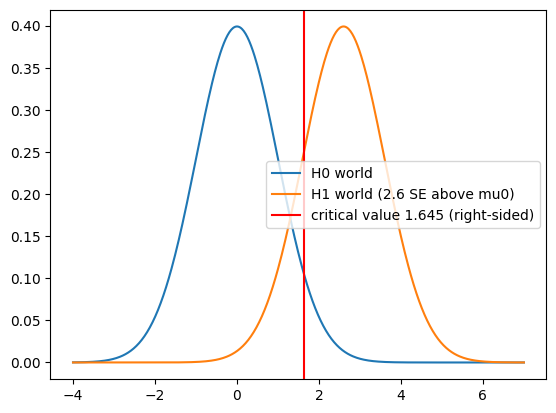

In [84]:
rng = np.random.default_rng(11)
means = rng.normal(1000, 3, size=(10_000, 9)).mean(axis=1)    # H0 true: mu = 1000
z = (means - 1000) / (3 / np.sqrt(9))
print("share of false alarms:", np.mean(np.abs(z) > 1.96))    # about 0.05
grid = np.linspace(-4, 7, 500)
plt.plot(grid, stats.norm.pdf(grid), label="H0 world")
plt.plot(grid, stats.norm.pdf(grid, loc=2.6), label="H1 world (2.6 SE above mu0)")
plt.axvline(1.645, color="red", label="critical value 1.645 (right-sided)")
plt.legend(); plt.show()

### 6.2 $\alpha$, $\beta$ and power

Slides: *Type I error*, *Type II error*, *Only one error is controllable*, *Trade-off and power*,
*Computing $\beta$ concretely -- milk*. $\beta=P(\text{keep }H_0\mid\mu=\mu_1)$, power $=1-\beta$.
Step 1: acceptance region for $\bar X$ in the $H_0$ world; step 2: probability of landing there when
$\mu=\mu_1$.

In [85]:
se = 3 / np.sqrt(9)
lo, hi = 1000 - 1.96 * se, 1000 + 1.96 * se                     # [998.04, 1001.96]
beta = stats.norm.cdf((hi - 1002) / se) - stats.norm.cdf((lo - 1002) / se)
print(f"[{lo:.2f}, {hi:.2f}], beta = {beta:.3f}, power = {1 - beta:.3f}")  # [998.04, 1001.96] 0.484 0.516

[998.04, 1001.96], beta = 0.484, power = 0.516


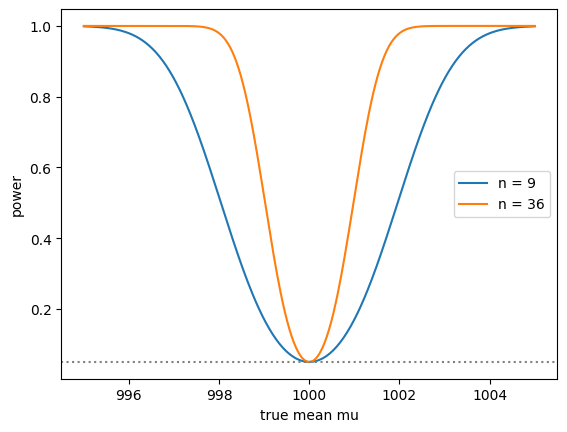

In [86]:
# power curve (slide "Trade-off and power"): power at every true mu for n = 9 and n = 36
mus = np.linspace(995, 1005, 400)
for n in (9, 36):
    se = 3 / np.sqrt(n)
    power = 1 - (stats.norm.cdf((1000 + 1.96 * se - mus) / se) - stats.norm.cdf((1000 - 1.96 * se - mus) / se))
    plt.plot(mus, power, label=f"n = {n}")
plt.axhline(0.05, ls=":", color="gray"); plt.xlabel("true mean mu"); plt.ylabel("power")
plt.legend(); plt.show()

Slides: *Four levers for more power* and *$\beta$ and power with Python* (statsmodels `NormalIndPower`, effect size $d=|\mu_1-\mu_0|/\sigma=2/3$).

In [87]:
for n in (9, 36):                        # milk: mu0 = 1000, true mu1 = 1002, sigma = 3
    se = 3 / np.sqrt(n)
    lo, hi = 1000 - 1.96 * se, 1000 + 1.96 * se         # acceptance region (H0 world)
    beta = stats.norm.cdf(hi, 1002, se) - stats.norm.cdf(lo, 1002, se)  # mu1 world
    print(f"n = {n}: beta = {beta:.3f}, power = {1 - beta:.3f}")
pw = NormalIndPower()                    # power of the z-test; ratio=0: one sample
print(round(pw.power(effect_size=2/3, nobs1=9, alpha=0.05, ratio=0), 3))          # 0.516
n80 = pw.solve_power(effect_size=2/3, power=0.80, alpha=0.05, ratio=0)
print(round(n80, 2), "->", math.ceil(n80))                                        # 17.66 -> n = 18

n = 9: beta = 0.484, power = 0.516
n = 36: beta = 0.021, power = 0.979
0.516
17.66 -> 18


### 6.3 Exercises

#### Exercise -- compute $\beta$ and power (two-sided)

$H_0:\mu=100$ vs. $H_1:\mu\neq100$, $\sigma=10$ known, $n=25$, $\alpha=0.05$, true $\mu_1=105$.
Find $\beta$ and the power.

In [88]:
# Your turn: acceptance region under H0, then probability under mu1
mu0, mu1, sigma, n = 100, 105, 10, 25

**Solution**

Step 1: $100\pm1.96\cdot2=[96.08;\,103.92]$. Step 2: $\beta=\Phi(-0.54)-\Phi(-4.46)$.

In [89]:
se = 10 / np.sqrt(25)
lo, hi = 100 - 1.96 * se, 100 + 1.96 * se
beta = stats.norm.cdf((hi - 105) / se) - stats.norm.cdf((lo - 105) / se)
print(f"[{lo:.2f}, {hi:.2f}], beta = {beta:.4f}, power = {1 - beta:.4f}")  # [96.08, 103.92] 0.2946 0.7054

[96.08, 103.92], beta = 0.2946, power = 0.7054


#### Exercise -- power of a one-sided test

Now right-sided, $H_1:\mu>100$, with $\sigma=10$, $n=25$, $\alpha=0.05$, true $\mu_1=105$. Find the
power and compare with $0.7054$.

In [90]:
# Your turn: critical mean 100 + 1.645 * SE, then P(Xbar > critical mean | mu1)
mu0, mu1, sigma, n = 100, 105, 10, 25

**Solution**

Rule: $\bar x_{\text{crit}}=\mu_0+z_{0.95}\cdot\mathrm{SE}$; power $=P(\bar X>\bar x_{\text{crit}}\mid\mu_1)$.

In [91]:
se = 2
x_crit = 100 + 1.645 * se                                 # 103.29
power = 1 - stats.norm.cdf((x_crit - 105) / se)           # 1 - Phi(-0.855)
print(round(x_crit, 2), round(power, 4))                  # 103.29 0.8037 (unrounded z: 0.8038)

103.29 0.8037


## 7 Summary

- **Foundations:** $Z=(X-\mu)/\sigma$; $\bar X$ has $E(\bar X)=\mu$, $\mathrm{SE}=\sigma/\sqrt n$, and is
  approximately normal for large $n$ (CLT).
- **Confidence interval:** $\bar x\pm z_{1-\alpha/2}\,\sigma/\sqrt n$ (known $\sigma$) or
  $\bar x\pm t_{1-\alpha/2,n-1}\,s/\sqrt n$; sample size $n\ge(z_{1-\alpha/2}\sigma/e)^2$.
- **Test (two-sided):** reject if $|Z_n|>z_{1-\alpha/2}$ or $|T_n|>t_{1-\alpha/2,n-1}$ -- equivalently $p<\alpha$.
- **One-sided:** the whole $\alpha$ on the $H_1$ side; one-sided $p$ without doubling.
- **Errors:** $\alpha$ is controlled; $\beta$ falls with $n$ (power $=1-\beta$).
- **Five pitfalls:** $p$ is not $P(H_0)$; a CI is not a probability for $\mu$; keeping $H_0$ does not
  prove it; the direction is fixed before the data; significant does not mean important.

## A Appendix: Estimators and the Law of Large Numbers

### A.1 Properties of estimators

Slides: *What makes a good estimator?* and *Properties of estimators -- the formal criteria*:
unbiased $E(\hat\theta)=\theta$, efficient (smallest variance among unbiased), consistent
$\hat\theta_n\xrightarrow{P}\theta$.

Slide: *Why divide by $n-1$ in $s^2$?* Simulation with $100\,000$ samples of size $n=4$ from
$N(50,5^2)$: the average of $s^2$ is about $25$ with $n-1$, but about $\frac34\cdot25=18.75$ with $n$.

In [92]:
rng = np.random.default_rng(5)
samples = rng.normal(50, 5, size=(100_000, 4))
print(round(samples.var(axis=1, ddof=1).mean(), 2), round(samples.var(axis=1, ddof=0).mean(), 2))   # 24.97 18.73

24.97 18.73


#### Exercise -- properties of estimators: egg weight

$n=4$ eggs, $\mu=50$ g, $\sigma^2=25$ g$^2$. Estimators: $\hat\mu_A=(X_1+X_2+X_3+X_4)/4$,
$\hat\mu_B=(X_1+X_4)/2$, $\hat\mu_C=(X_1+2X_2+X_3+X_4)/5$, $\hat\mu_D=(X_1+X_2+X_3)/4$.
a) Unbiased? Bias? b) Variances. c) Which should the farmer use? d) Which of $\bar X_n$ and
$(X_1+X_n)/2$ is consistent?

In [93]:
# Your turn: E = mu * sum(a_i), Var = sigma^2 * sum(a_i^2)
weights = {"A": [1/4, 1/4, 1/4, 1/4], "B": [1/2, 0, 0, 1/2],
           "C": [1/5, 2/5, 1/5, 1/5], "D": [1/4, 1/4, 1/4, 0]}

**Solution**

Rules: $E(\sum a_iX_i)=\mu\sum a_i$, $\mathrm{Var}(\sum a_iX_i)=\sigma^2\sum a_i^2$. c) $\bar X_4$ (unbiased and efficient). d) only $\bar X_n$.

In [94]:
weights = {"A": [1/4, 1/4, 1/4, 1/4], "B": [1/2, 0, 0, 1/2],
           "C": [1/5, 2/5, 1/5, 1/5], "D": [1/4, 1/4, 1/4, 0]}
for k, w in weights.items():
    w = np.array(w)
    print(f"{k}: E = {50 * w.sum():.1f}, bias = {50 * w.sum() - 50:+.1f}, Var = {25 * np.sum(w ** 2):.4f}")
# the simulation of the solution slide
rng = np.random.default_rng(1)
m = rng.normal(50, 5, size=(10_000, 4))       # 10 000 samples of 4 eggs
A = m.mean(axis=1)
B = (m[:, 0] + m[:, 3]) / 2
C = (m[:, 0] + 2 * m[:, 1] + m[:, 2] + m[:, 3]) / 5
D = (m[:, 0] + m[:, 1] + m[:, 2]) / 4
print(np.round([A.mean(), B.mean(), C.mean(), D.mean()], 2))
print(np.round([A.var(ddof=1), B.var(ddof=1), C.var(ddof=1), D.var(ddof=1)], 2))

A: E = 50.0, bias = +0.0, Var = 6.2500
B: E = 50.0, bias = +0.0, Var = 12.5000
C: E = 50.0, bias = +0.0, Var = 7.0000
D: E = 37.5, bias = -12.5, Var = 4.6875
[49.95 49.95 49.95 37.47]
[ 6.14 12.52  6.87  4.52]


### A.2 Law of large numbers

Slides: *The law of large numbers -- intuition* and *formal statement*:
$\bar X_n\xrightarrow{P}\mu$. Fair die, $E(X)=3.5$: the running mean settles down inside the funnel
$\mu\pm1.96\,\sigma/\sqrt n$ ($\pm1.06$ at $n=10$, $\pm0.33$ at $n=100$, $\pm0.11$ at $n=1000$).

n =   10: 3.5 +- 1.06
n =  100: 3.5 +- 0.33
n = 1000: 3.5 +- 0.11


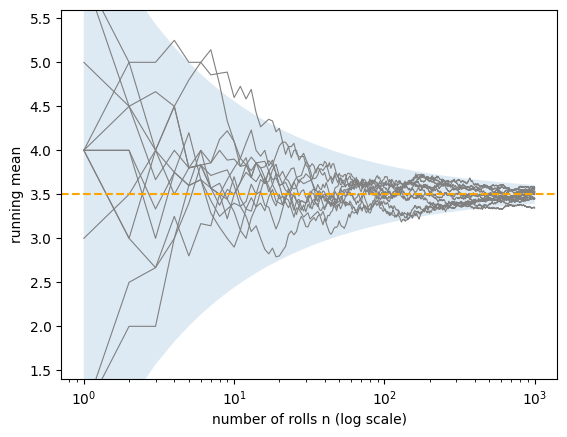

In [95]:
sd = np.sqrt(35 / 12)
for n in (10, 100, 1000):
    print(f"n = {n:>4}: 3.5 +- {1.96 * sd / np.sqrt(n):.2f}")
rng = np.random.default_rng(7)
rolls = rng.integers(1, 7, size=(12, 1000))              # 12 sequences of 1000 rolls
run = np.cumsum(rolls, axis=1) / np.arange(1, 1001)
n = np.arange(1, 1001)
plt.fill_between(n, 3.5 - 1.96 * sd / np.sqrt(n), 3.5 + 1.96 * sd / np.sqrt(n), alpha=0.15)
plt.plot(n, run.T, color="gray", lw=0.8)
plt.axhline(3.5, color="orange", ls="--"); plt.xscale("log"); plt.ylim(1.4, 5.6)
plt.xlabel("number of rolls n (log scale)"); plt.ylabel("running mean"); plt.show()

## Key Python commands

The commands of the summary slide *Summary 6 -- important Python commands*, with results for the running examples.

In [96]:
x = milk                                                       # any data vector
n = len(x)
print(f"{stats.norm.cdf(1.96):.4f} {stats.norm.sf(1.96):.4f}")    # Phi(z), 1 - Phi(z):           0.9750 0.0250
print(f"{stats.norm.ppf(0.975):.4f}")                          # quantile z_p:                 1.9600
print(f"{stats.norm.cdf(997, 1000, 3):.4f}")                   # P(X <= x), N(1000, 3^2):      0.1587
print(f"{stats.t.cdf(-2.11, df=15):.4f} {stats.t.ppf(0.975, df=8):.4f}")   # F_t,df(t), t_p,df: 0.0260 2.3060
lo, hi = stats.norm.interval(0.95, loc=x.mean(), scale=3 / np.sqrt(n))      # CI, sigma known
print(f"[{lo:.2f}, {hi:.2f}]")                                 # [999.04, 1002.96]
lo, hi = stats.t.interval(0.95, df=n - 1, loc=x.mean(), scale=x.std(ddof=1) / np.sqrt(n))  # sigma unknown
print(f"[{lo:.2f}, {hi:.2f}]")                                 # [998.10, 1003.90]
res = stats.ttest_1samp(x, popmean=1000)                       # two-sided t-test
ci = res.confidence_interval(0.95)
print(f"t = {res.statistic:.4f}, df = {res.df}, p = {res.pvalue:.4f}, CI = [{ci.low:.2f}, {ci.high:.2f}]")
res = stats.ttest_1samp(x, 1000, alternative="less")           # one-sided: "less" / "greater"
print(f"p (left-sided) = {res.pvalue:.4f}")                    # 0.7751
z = (x.mean() - 1000) / (3 / np.sqrt(n))
print(f"z-test p = {2 * stats.norm.sf(abs(z)):.4f}")           # two-sided: 0.3173
print(math.ceil((1.96 * 3 / 1) ** 2))                          # sample size for margin e = 1:  35
print(math.ceil(NormalIndPower().solve_power(effect_size=2/3, power=0.8, alpha=0.05, ratio=0)))  # n for 80 % power: 18

0.9750 0.0250
1.9600
0.1587
0.0260 2.3060
[999.04, 1002.96]
[998.10, 1003.90]
t = 0.7947, df = 8, p = 0.4497, CI = [998.10, 1003.90]
p (left-sided) = 0.7751
z-test p = 0.3173
35
18
